In [2]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed" / "detection"

DATA_YAML = PROCESSED_DIR / "data.yaml"

TRAIN_IMAGES_DIR = PROCESSED_DIR / "images" / "train"
VAL_IMAGES_DIR = PROCESSED_DIR / "images" / "val"
TEST_IMAGES_DIR = PROCESSED_DIR / "images" / "test"

TRAIN_LABELS_DIR = PROCESSED_DIR / "labels" / "train"
VAL_LABELS_DIR = PROCESSED_DIR / "labels" / "val"
TEST_LABELS_DIR = PROCESSED_DIR / "labels" / "test"

print("Projet :", PROJECT_ROOT)
print("Dataset YOLO :", PROCESSED_DIR)
print("data.yaml :", DATA_YAML)

Projet : c:\Users\yassmine\Downloads\industrial-defect-detection
Dataset YOLO : c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection
data.yaml : c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\data.yaml


In [3]:
print("data.yaml existe :", DATA_YAML.exists())
print("Train images :", len(list(TRAIN_IMAGES_DIR.glob("*.jpg"))))
print("Val images :", len(list(VAL_IMAGES_DIR.glob("*.jpg"))))
print("Test images :", len(list(TEST_IMAGES_DIR.glob("*.jpg"))))

data.yaml existe : True
Train images : 1260
Val images : 270
Test images : 270


In [4]:
%pip install ultralytics

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import ultralytics

print("Ultralytics :", ultralytics.__version__)

Ultralytics : 8.4.172


In [6]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

In [7]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print(model)

YOLO(
  (model): DetectionModel(
    (model): Sequential(
      (0): Conv(
        (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(16, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (1): Conv(
        (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (2): C3k2(
        (cv1): Conv(
          (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, bias=True, track_running_stats=True)
          (act): SiLU(inplace=True)
        )
        (cv2): Conv(
          (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn): BatchNorm2d(64, eps=0.001, momentum=

In [8]:
test_image = str(TRAIN_IMAGES_DIR / "crazing_1.jpg")

results = model.predict(
    source=test_image,
    conf=0.25,
    save=False
)

print("Prédiction terminée.")


image 1/1 c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\images\train\crazing_1.jpg: 640x640 (no detections), 316.2ms
Speed: 82.9ms preprocess, 316.2ms inference, 11.2ms postprocess per image at shape (1, 3, 640, 640)
Prédiction terminée.


In [9]:
results[0].show()

In [10]:
from ultralytics.data.utils import check_det_dataset

dataset_info = check_det_dataset(str(DATA_YAML))

print("Dataset chargé avec succès.")
print("Classes :", dataset_info["names"])

Dataset chargé avec succès.
Classes : {0: 'crazing', 1: 'inclusion', 2: 'patches', 3: 'pitted_surface', 4: 'rolled-in_scale', 5: 'scratches'}


In [11]:
sample_label = TRAIN_LABELS_DIR / "crazing_1.txt"

print(sample_label.read_text())

0 0.487500 0.490000 0.955000 0.960000


In [12]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

In [13]:
results = model.train(
    data=str(DATA_YAML),
    epochs=10,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project=str(PROJECT_ROOT / "runs"),
    name="yolo11n_neu_fast"
)

New https://pypi.org/project/ultralytics/8.4.175 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.172  Python-3.13.5 torch-2.14.1+cpu CPU (Intel Core i5-1035G1 1.00GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=

In [14]:
results_dir = PROJECT_ROOT / "runs" / "yolo11n_neu_fast"

print("Résultats :", results_dir)
print("Fichiers :")

for file in sorted(results_dir.iterdir()):
    print("-", file.name)

Résultats : c:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_fast
Fichiers :
- args.yaml
- BoxF1_curve.png
- BoxP_curve.png
- BoxPR_curve.png
- BoxR_curve.png
- confusion_matrix.png
- confusion_matrix_normalized.png
- labels.jpg
- results.csv
- results.png
- train_batch0.jpg
- train_batch1.jpg
- train_batch2.jpg
- val_batch0_labels.jpg
- val_batch0_pred.jpg
- val_batch1_labels.jpg
- val_batch1_pred.jpg
- val_batch2_labels.jpg
- val_batch2_pred.jpg
- weights


In [15]:
BEST_MODEL = results_dir / "weights" / "best.pt"

print("Best model :", BEST_MODEL)
print("Existe :", BEST_MODEL.exists())

Best model : c:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_fast\weights\best.pt
Existe : True


In [16]:
import pandas as pd

results_dir = PROJECT_ROOT / "runs" / "yolo11n_neu_fast"

results_csv = results_dir / "results.csv"

df = pd.read_csv(results_csv)

print(df.columns.tolist())

['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


In [17]:
print(df.tail())

   epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  \
5      6  2003.93         1.67689         1.99618         1.69239   
6      7  2385.60         1.64287         1.88776         1.63909   
7      8  2761.65         1.59559         1.80549         1.60984   
8      9  3026.37         1.54758         1.73523         1.58064   
9     10  3429.23         1.52580         1.69752         1.55708   

   metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
5               0.60626            0.52361           0.55589   
6               0.47334            0.59184           0.54867   
7               0.51331            0.59761           0.57078   
8               0.59276            0.62039           0.63454   
9               0.60867            0.64643           0.64975   

   metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/pg0  \
5              0.27102       1.70368       1.88470       1.62675  0.000505   
6              0.28460       1.65031       1

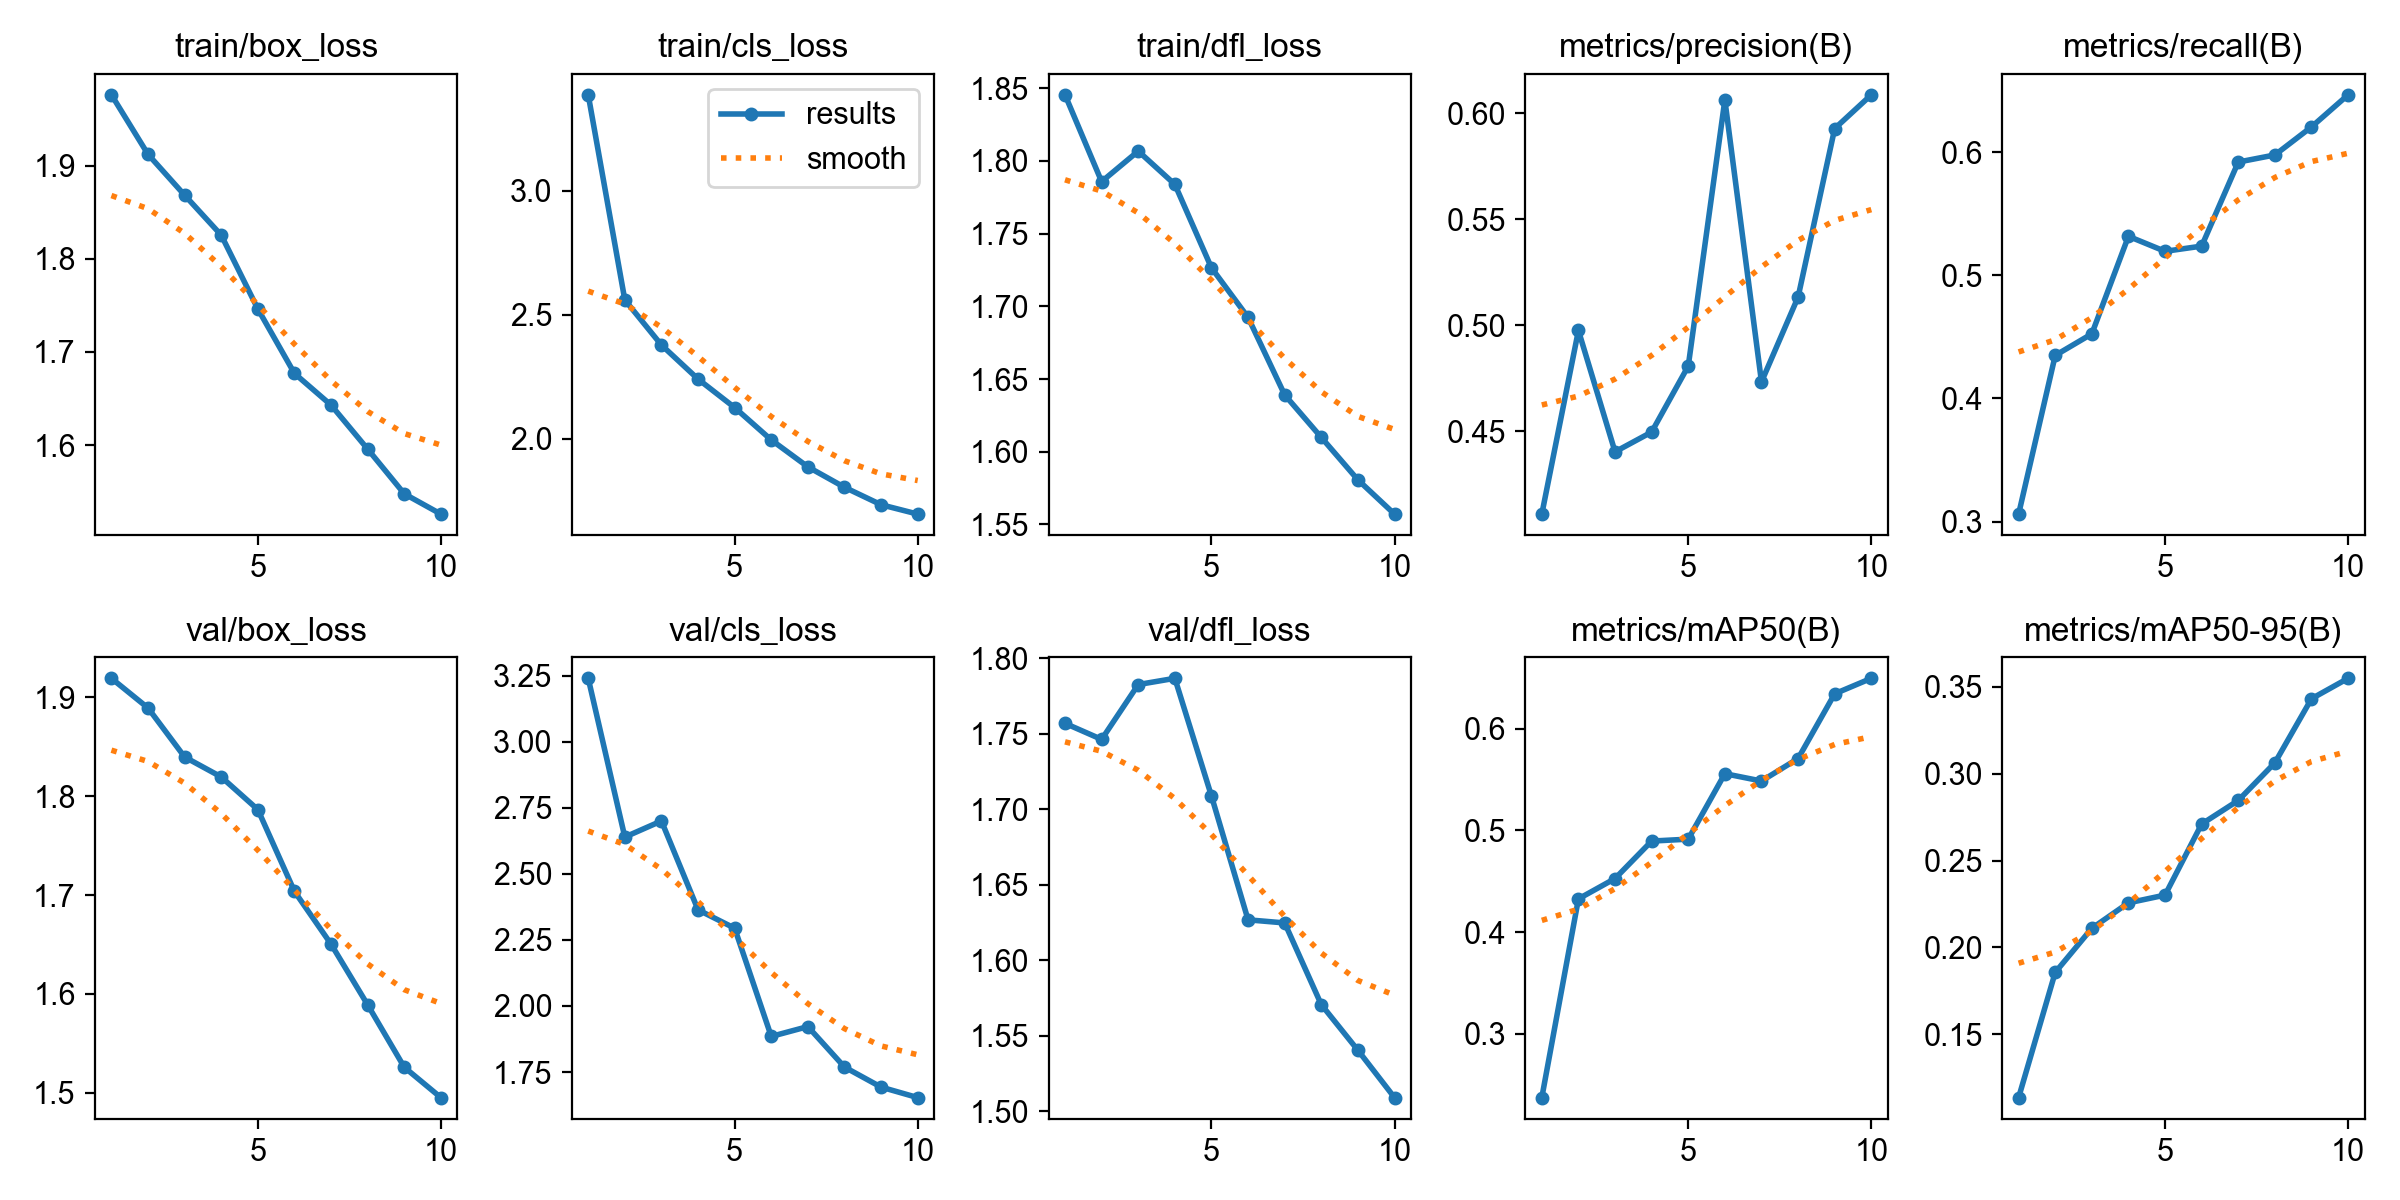

In [18]:
from IPython.display import display
from PIL import Image

results_image = results_dir / "results.png"

display(Image.open(results_image))

In [19]:
from ultralytics import YOLO

BEST_MODEL = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_fast"
    / "weights"
    / "best.pt"
)

model = YOLO(str(BEST_MODEL))

In [20]:
results = model.train(
    data=str(DATA_YAML),
    epochs=15,
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    project=str(PROJECT_ROOT / "runs"),
    name="yolo11n_neu_finetuned"
)

New https://pypi.org/project/ultralytics/8.4.175 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.172  Python-3.13.5 torch-2.14.1+cpu CPU (Intel Core i5-1035G1 1.00GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=

In [21]:
import pandas as pd

FINETUNED_DIR = PROJECT_ROOT / "runs" / "yolo11n_neu_finetuned"

df_finetuned = pd.read_csv(FINETUNED_DIR / "results.csv")

print(df_finetuned.tail())

    epoch     time  train/box_loss  train/cls_loss  train/dfl_loss  \
10     11  3751.61         1.48807         1.55222         1.53164   
11     12  4362.85         1.44941         1.49574         1.52071   
12     13  4886.02         1.41326         1.47002         1.49040   
13     14  5398.20         1.39648         1.42544         1.48000   
14     15  5938.70         1.36570         1.39807         1.47355   

    metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  \
10               0.71779            0.62548           0.66193   
11               0.75978            0.62503           0.69814   
12               0.70109            0.65180           0.69073   
13               0.75035            0.63473           0.71054   
14               0.73386            0.65486           0.70601   

    metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss    lr/pg0  \
10              0.36303       1.46975       1.52862       1.48985  0.000340   
11              0.38433       

In [22]:
best_epoch = df_finetuned["metrics/mAP50(B)"].idxmax()

print("Meilleur epoch :", best_epoch + 1)
print("Meilleur mAP50 :", df_finetuned.loc[best_epoch, "metrics/mAP50(B)"])
print("mAP50-95 :", df_finetuned.loc[best_epoch, "metrics/mAP50-95(B)"])
print("Precision :", df_finetuned.loc[best_epoch, "metrics/precision(B)"])
print("Recall :", df_finetuned.loc[best_epoch, "metrics/recall(B)"])

Meilleur epoch : 14
Meilleur mAP50 : 0.71054
mAP50-95 : 0.38799
Precision : 0.75035
Recall : 0.63473


In [23]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

DATA_YAML = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "detection"
    / "data.yaml"
)

BEST_MODEL = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_finetuned"
    / "weights"
    / "best.pt"
)

TEST_IMAGES_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "detection"
    / "images"
    / "test"
)

print("Fichier data.yaml :", DATA_YAML.exists())
print("Modèle best.pt :", BEST_MODEL.exists())
print("Images de test :", len(list(TEST_IMAGES_DIR.glob("*.jpg"))))

Fichier data.yaml : True
Modèle best.pt : True
Images de test : 270


In [24]:
from ultralytics import YOLO

model = YOLO(str(BEST_MODEL))

test_results = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=True,
    project=str(PROJECT_ROOT / "runs"),
    name="yolo11n_neu_test"
)

Ultralytics 8.4.172  Python-3.13.5 torch-2.14.1+cpu CPU (Intel Core i5-1035G1 1.00GHz)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 1.30.1 MB/s, size: 17.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\labels\test... 270 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 270/270 176.0it/s 1.5s0.1s
val: New cache created: C:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 6.9it/s 9.9s0.2ss
                   all        270        611      0.741       0.64      0.691      0.388
               crazing         45        103          1     0.03

In [25]:
print(f"Precision : {test_results.box.mp:.4f}")
print(f"Recall : {test_results.box.mr:.4f}")
print(f"mAP50 : {test_results.box.map50:.4f}")
print(f"mAP50-95 : {test_results.box.map:.4f}")

Precision : 0.7408
Recall : 0.6399
mAP50 : 0.6907
mAP50-95 : 0.3878


Image sélectionnée : crazing_110.jpg


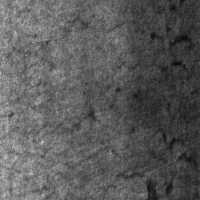

In [26]:
from pathlib import Path
from IPython.display import display
from PIL import Image

test_images = sorted(TEST_IMAGES_DIR.glob("*.jpg"))

# Sélectionner une image du jeu de test
test_image = test_images[0]

print("Image sélectionnée :", test_image.name)

# Prédire les défauts
predictions = model.predict(
    source=str(test_image),
    imgsz=320,
    conf=0.25,
    device="cpu",
    save=False,
    verbose=False
)

# Afficher l'image avec les boîtes prédites
annotated_image = predictions[0].plot()
annotated_image = annotated_image[:, :, ::-1]  # BGR vers RGB

display(Image.fromarray(annotated_image))

In [27]:
print("Nombre de défauts détectés :", len(predictions[0].boxes))

for box in predictions[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"Classe : {model.names[class_id]} | "
        f"Confiance : {confidence:.2%}"
    )

Nombre de défauts détectés : 0


Détections avec conf=0.05 : 11
Classe : crazing | Confiance : 13.16%
Classe : crazing | Confiance : 12.77%
Classe : crazing | Confiance : 12.38%
Classe : crazing | Confiance : 10.45%
Classe : crazing | Confiance : 10.13%
Classe : crazing | Confiance : 6.40%
Classe : crazing | Confiance : 6.20%
Classe : crazing | Confiance : 5.84%
Classe : crazing | Confiance : 5.67%
Classe : crazing | Confiance : 5.59%
Classe : crazing | Confiance : 5.09%


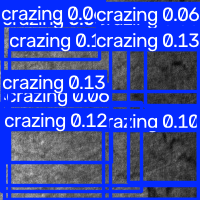

In [28]:
predictions_low_conf = model.predict(
    source=str(test_image),
    imgsz=320,
    conf=0.05,
    device="cpu",
    save=False,
    verbose=False
)

print(
    "Détections avec conf=0.05 :",
    len(predictions_low_conf[0].boxes)
)

for box in predictions_low_conf[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"Classe : {model.names[class_id]} | "
        f"Confiance : {confidence:.2%}"
    )

annotated = predictions_low_conf[0].plot()
display(Image.fromarray(annotated[:, :, ::-1]))

Nombre d'images patches : 45
Image sélectionnée : patches_1.jpg
Nombre de détections : 3
Classe : patches | Confiance : 83.62%
Classe : patches | Confiance : 70.81%
Classe : patches | Confiance : 61.77%


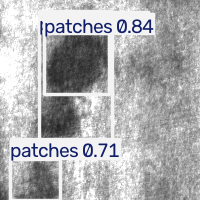

In [29]:
# Chercher une image patches dans le test set
patches_images = sorted(
    TEST_IMAGES_DIR.glob("patches_*.jpg")
)

print("Nombre d'images patches :", len(patches_images))

patches_image = patches_images[0]
print("Image sélectionnée :", patches_image.name)

patches_predictions = model.predict(
    source=str(patches_image),
    imgsz=320,
    conf=0.25,
    device="cpu",
    save=False,
    verbose=False
)

print(
    "Nombre de détections :",
    len(patches_predictions[0].boxes)
)

for box in patches_predictions[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"Classe : {model.names[class_id]} | "
        f"Confiance : {confidence:.2%}"
    )

annotated = patches_predictions[0].plot()
display(Image.fromarray(annotated[:, :, ::-1]))

In [30]:
xml_path = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "NEU-DET"
    / "ANNOTATIONS"
    / f"{test_image.stem}.xml"
)

print("Fichier XML :", xml_path)
print("XML trouvé :", xml_path.exists())

if xml_path.exists():
    print(xml_path.read_text(encoding="utf-8")[:5000])

Fichier XML : c:\Users\yassmine\Downloads\industrial-defect-detection\data\raw\NEU-DET\ANNOTATIONS\crazing_110.xml
XML trouvé : True
<annotation>
	<folder>cr</folder>
	<filename>crazing_110.jpg</filename>
	<source>
		<database>NEU-DET</database>
	</source>
	<size>
		<width>200</width>
		<height>200</height>
		<depth>1</depth>
	</size>
	<segmented>0</segmented>
	<object>
		<name>crazing</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>105</xmin>
			<ymin>18</ymin>
			<xmax>193</xmax>
			<ymax>75</ymax>
		</bndbox>
	</object>
	<object>
		<name>crazing</name>
		<pose>Unspecified</pose>
		<truncated>1</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>1</xmin>
			<ymin>16</ymin>
			<xmax>89</xmax>
			<ymax>79</ymax>
		</bndbox>
	</object>
</annotation>



ANNOTATIONS RÉELLES (XML)
Classe : crazing | Boîte : (105, 18, 193, 75)
Classe : crazing | Boîte : (1, 16, 89, 79)

PRÉDICTIONS YOLO (seuil de confiance = 5 %)
Classe : crazing | Confiance : 13.16% | Boîte : (2, 91, 198, 185)
Classe : crazing | Confiance : 12.77% | Boîte : (128, 49, 199, 182)
Classe : crazing | Confiance : 12.38% | Boîte : (4, 129, 198, 199)
Classe : crazing | Confiance : 10.45% | Boîte : (103, 130, 200, 200)
Classe : crazing | Confiance : 10.13% | Boîte : (9, 49, 198, 199)
Classe : crazing | Confiance : 6.40% | Boîte : (145, 23, 199, 107)
Classe : crazing | Confiance : 6.20% | Boîte : (1, 0, 99, 59)
Classe : crazing | Confiance : 5.84% | Boîte : (6, 104, 111, 162)
Classe : crazing | Confiance : 5.67% | Boîte : (1, 102, 141, 191)
Classe : crazing | Confiance : 5.59% | Boîte : (110, 27, 199, 199)
Classe : crazing | Confiance : 5.09% | Boîte : (2, 5, 200, 105)


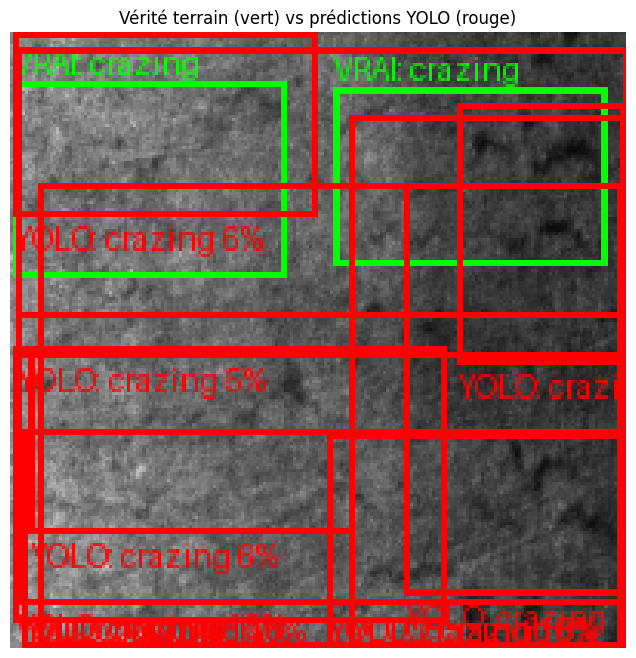

In [31]:
import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# 1. Charger l'image originale
image = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(image)

# 2. Lire les vérités terrain depuis le XML
tree = ET.parse(xml_path)
root = tree.getroot()

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("ANNOTATIONS RÉELLES (XML)")

for obj in root.findall("object"):
    class_name = obj.findtext("name")
    box = obj.find("bndbox")

    xmin = int(box.findtext("xmin"))
    ymin = int(box.findtext("ymin"))
    xmax = int(box.findtext("xmax"))
    ymax = int(box.findtext("ymax"))

    print(
        f"Classe : {class_name} | "
        f"Boîte : ({xmin}, {ymin}, {xmax}, {ymax})"
    )

    # Vert = annotation réelle
    draw.rectangle(
        [xmin, ymin, xmax, ymax],
        outline="lime",
        width=2
    )
    draw.text(
        (xmin, max(0, ymin - 12)),
        f"VRAI: {class_name}",
        fill="lime"
    )

# 3. Ajouter les prédictions YOLO
print("\nPRÉDICTIONS YOLO (seuil de confiance = 5 %)")

for box in predictions_low_conf[0].boxes:
    coords = box.xyxy[0].cpu().numpy()
    xmin, ymin, xmax, ymax = map(int, coords)

    class_id = int(box.cls[0].item())
    confidence = float(box.conf[0].item())
    class_name = class_names[class_id]

    print(
        f"Classe : {class_name} | "
        f"Confiance : {confidence:.2%} | "
        f"Boîte : ({xmin}, {ymin}, {xmax}, {ymax})"
    )

    # Rouge = prédiction du modèle
    draw.rectangle(
        [xmin, ymin, xmax, ymax],
        outline="red",
        width=2
    )
    draw.text(
        (xmin, min(image.height - 12, ymax + 2)),
        f"YOLO: {class_name} {confidence:.0%}",
        fill="red"
    )

# 4. Afficher le résultat
plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.title("Vérité terrain (vert) vs prédictions YOLO (rouge)")
plt.axis("off")
plt.show()

In [32]:

from ultralytics import YOLO
from pathlib import Path

BEST_MODEL = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_finetuned"
    / "weights"
    / "best.pt"
)

model = YOLO(str(BEST_MODEL))

for threshold in [0.05, 0.10, 0.25, 0.50]:
    results = model.predict(
        source=str(test_image),
        imgsz=320,
        conf=threshold,
        iou=0.45,
        device="cpu",
        save=False,
        verbose=False
    )

    boxes = results[0].boxes

    print(f"\n--- Seuil : {threshold:.0%} ---")
    print("Nombre de détections :", len(boxes))

    for box in boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        coordinates = [
            round(value, 1)
            for value in box.xyxy[0].cpu().tolist()
        ]

        print(
            f"Classe : {model.names[class_id]} | "
            f"Confiance : {confidence:.2%} | "
            f"Boîte : {coordinates}"
        )



--- Seuil : 5% ---
Nombre de détections : 7
Classe : crazing | Confiance : 13.16% | Boîte : [3.0, 91.6, 198.9, 185.5]
Classe : crazing | Confiance : 12.77% | Boîte : [128.3, 49.6, 199.7, 182.2]
Classe : crazing | Confiance : 10.45% | Boîte : [103.3, 130.6, 200.0, 200.0]
Classe : crazing | Confiance : 6.40% | Boîte : [145.2, 23.7, 199.4, 107.1]
Classe : crazing | Confiance : 6.20% | Boîte : [1.8, 0.6, 99.9, 59.7]
Classe : crazing | Confiance : 5.84% | Boîte : [6.4, 104.6, 111.5, 162.9]
Classe : crazing | Confiance : 5.09% | Boîte : [2.2, 6.0, 200.0, 105.5]

--- Seuil : 10% ---
Nombre de détections : 3
Classe : crazing | Confiance : 13.16% | Boîte : [3.0, 91.6, 198.9, 185.5]
Classe : crazing | Confiance : 12.77% | Boîte : [128.3, 49.6, 199.7, 182.2]
Classe : crazing | Confiance : 10.45% | Boîte : [103.3, 130.6, 200.0, 200.0]

--- Seuil : 25% ---
Nombre de détections : 0

--- Seuil : 50% ---
Nombre de détections : 0


In [33]:

from pathlib import Path

images_to_test = [
    TEST_IMAGES_DIR / "crazing_110.jpg",
    sorted(TEST_IMAGES_DIR.glob("patches_*.jpg"))[0],
    sorted(TEST_IMAGES_DIR.glob("rolled-in_scale_*.jpg"))[0],
]

for image_path in images_to_test:
    print(f"\n{'=' * 55}")
    print("Image :", image_path.name)

    results = model.predict(
        source=str(image_path),
        imgsz=320,
        conf=0.10,
        iou=0.45,
        device="cpu",
        save=False,
        verbose=False
    )

    boxes = results[0].boxes
    print("Nombre de détections :", len(boxes))

    for box in boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())

        print(
            f"{model.names[class_id]} : "
            f"{confidence:.2%}"
        )



Image : crazing_110.jpg
Nombre de détections : 3
crazing : 13.16%
crazing : 12.77%
crazing : 10.45%

Image : patches_1.jpg
Nombre de détections : 3
patches : 83.62%
patches : 70.81%
patches : 20.28%

Image : rolled-in_scale_10.jpg
Nombre de détections : 3
rolled-in_scale : 55.70%
rolled-in_scale : 53.52%
rolled-in_scale : 15.59%



Image : crazing_110.jpg
ANNOTATIONS RÉELLES (vert)
crazing (105, 18, 193, 75)
crazing (1, 16, 89, 79)
PRÉDICTIONS YOLO (rouge)
crazing | 13.16% | (3, 92, 199, 186)
crazing | 12.77% | (128, 50, 200, 182)
crazing | 12.38% | (4, 129, 199, 200)
crazing | 10.45% | (103, 131, 200, 200)
crazing | 10.13% | (9, 49, 199, 199)


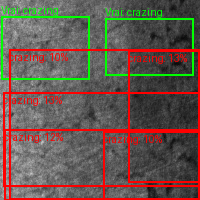


Image : patches_1.jpg
ANNOTATIONS RÉELLES (vert)
patches (43, 10, 106, 97)
patches (32, 91, 81, 148)
patches (23, 156, 62, 198)
PRÉDICTIONS YOLO (rouge)
patches | 83.62% | (44, 13, 110, 95)
patches | 70.81% | (11, 159, 61, 200)
patches | 61.77% | (40, 11, 112, 150)
patches | 20.28% | (35, 94, 79, 146)


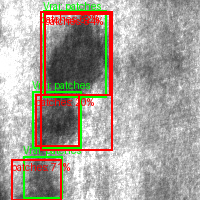


Image : rolled-in_scale_10.jpg
ANNOTATIONS RÉELLES (vert)
rolled-in_scale (59, 39, 122, 71)
rolled-in_scale (54, 83, 144, 139)
PRÉDICTIONS YOLO (rouge)
rolled-in_scale | 55.70% | (58, 96, 136, 137)
rolled-in_scale | 53.52% | (60, 35, 119, 68)
rolled-in_scale | 26.97% | (55, 88, 171, 139)
rolled-in_scale | 15.39% | (75, 36, 120, 70)
rolled-in_scale | 10.93% | (58, 37, 143, 139)


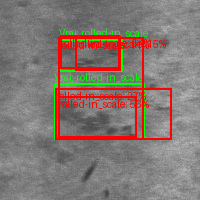

In [34]:

import xml.etree.ElementTree as ET
from PIL import Image, ImageDraw
from IPython.display import display

def compare_boxes(image_path, model, confidence=0.10):
    # Charger l'image originale
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    # Lire les annotations réelles du XML
    xml_path = (
        PROJECT_ROOT
        / "data" / "raw" / "NEU-DET"
        / "ANNOTATIONS"
        / f"{image_path.stem}.xml"
    )

    root = ET.parse(xml_path).getroot()

    print(f"\nImage : {image_path.name}")
    print("ANNOTATIONS RÉELLES (vert)")

    for obj in root.findall("object"):
        class_name = obj.findtext("name")
        box = obj.find("bndbox")

        x1 = int(float(box.findtext("xmin")))
        y1 = int(float(box.findtext("ymin")))
        x2 = int(float(box.findtext("xmax")))
        y2 = int(float(box.findtext("ymax")))

        print(class_name, (x1, y1, x2, y2))

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="lime",
            width=2
        )
        draw.text(
            (x1, max(0, y1 - 12)),
            f"Vrai: {class_name}",
            fill="lime"
        )

    # Prédictions du modèle
    results = model.predict(
        source=str(image_path),
        imgsz=320,
        conf=confidence,
        device="cpu",
        save=False,
        verbose=False
    )

    print("PRÉDICTIONS YOLO (rouge)")

    for box in results[0].boxes:
        class_id = int(box.cls[0].item())
        score = float(box.conf[0].item())
        x1, y1, x2, y2 = [
            int(round(v))
            for v in box.xyxy[0].cpu().tolist()
        ]
        class_name = model.names[class_id]

        print(
            f"{class_name} | {score:.2%} | "
            f"{(x1, y1, x2, y2)}"
        )

        draw.rectangle(
            [x1, y1, x2, y2],
            outline="red",
            width=2
        )
        draw.text(
            (x1, min(image.height - 12, y1 + 2)),
            f"{class_name}: {score:.0%}",
            fill="red"
        )

    display(image)

compare_boxes(TEST_IMAGES_DIR / "crazing_110.jpg", model)
compare_boxes(TEST_IMAGES_DIR / "patches_1.jpg", model)
compare_boxes(TEST_IMAGES_DIR / "rolled-in_scale_10.jpg", model)


In [35]:

from collections import Counter
from pathlib import Path

splits = ["train", "val", "test"]

for split in splits:
    labels_dir = (
        PROJECT_ROOT
        / "data"
        / "processed"
        / "detection"
        / "labels"
        / split
    )

    class_counts = Counter()
    images_with_crazing = 0
    total_boxes = 0
    empty_labels = 0

    for label_file in labels_dir.glob("*.txt"):
        lines = [
            line.strip()
            for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            empty_labels += 1

        image_has_crazing = False

        for line in lines:
            values = line.split()
            class_id = int(values[0])
            class_counts[class_id] += 1
            total_boxes += 1

            # Classe 0 = crazing
            if class_id == 0:
                image_has_crazing = True

        if image_has_crazing:
            images_with_crazing += 1

    print(f"\n--- {split.upper()} ---")
    print("Fichiers d'annotations :", len(list(labels_dir.glob("*.txt"))))
    print("Images avec crazing :", images_with_crazing)
    print("Boîtes crazing :", class_counts[0])
    print("Nombre total de boîtes :", total_boxes)
    print("Fichiers sans annotation :", empty_labels)



--- TRAIN ---
Fichiers d'annotations : 1260
Images avec crazing : 210
Boîtes crazing : 491
Nombre total de boîtes : 2952
Fichiers sans annotation : 0

--- VAL ---
Fichiers d'annotations : 270
Images avec crazing : 45
Boîtes crazing : 95
Nombre total de boîtes : 626
Fichiers sans annotation : 0

--- TEST ---
Fichiers d'annotations : 270
Images avec crazing : 45
Boîtes crazing : 103
Nombre total de boîtes : 611
Fichiers sans annotation : 0


In [36]:

import xml.etree.ElementTree as ET

image_name = "crazing_110"
xml_path = (
    PROJECT_ROOT / "data" / "raw" / "NEU-DET"
    / "ANNOTATIONS" / f"{image_name}.xml"
)
label_path = (
    PROJECT_ROOT / "data" / "processed" / "detection"
    / "labels" / "test" / f"{image_name}.txt"
)

print("XML trouvé :", xml_path.exists())
print("Label YOLO trouvé :", label_path.exists())

# 1. Afficher les coordonnées originales du XML
root = ET.parse(xml_path).getroot()
width = int(root.findtext("size/width"))
height = int(root.findtext("size/height"))

print("\nANNOTATIONS XML")
for obj in root.findall("object"):
    name = obj.findtext("name")
    box = obj.find("bndbox")
    coords = [
        int(float(box.findtext(k)))
        for k in ["xmin", "ymin", "xmax", "ymax"]
    ]
    print(name, coords)

# 2. Afficher les coordonnées normalisées du fichier YOLO
print("\nANNOTATIONS YOLO")
for line in label_path.read_text().splitlines():
    values = line.split()
    class_id = int(values[0])
    x_center, y_center, box_width, box_height = map(float, values[1:])

    # Conversion vers les coordonnées pixels
    x1 = (x_center - box_width / 2) * width
    y1 = (y_center - box_height / 2) * height
    x2 = (x_center + box_width / 2) * width
    y2 = (y_center + box_height / 2) * height

    print(
        model.names[class_id],
        [round(x1), round(y1), round(x2), round(y2)]
    )


XML trouvé : True
Label YOLO trouvé : True

ANNOTATIONS XML
crazing [105, 18, 193, 75]
crazing [1, 16, 89, 79]

ANNOTATIONS YOLO
crazing [105, 18, 193, 75]
crazing [1, 16, 89, 79]


In [37]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection"
)

BEST_MODEL = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_finetuned"
    / "weights"
    / "best.pt"
)

DATA_YAML = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "detection"
    / "data.yaml"
)

model = YOLO(str(BEST_MODEL))

results = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=320,
    batch=4,
    device="cpu",
    workers=0,
    plots=True
)

print("\nRésultats par classe :")
print("Classes :", model.names)
print("Précision :", results.box.p)
print("Rappel :", results.box.r)
print("mAP50 :", results.box.ap50)
print("mAP50-95 :", results.box.ap)

Ultralytics 8.4.172  Python-3.13.5 torch-2.14.1+cpu CPU (Intel Core i5-1035G1 1.00GHz)
YOLO11n summary (fused): 100 layers, 2,583,322 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 20.79.9 MB/s, size: 13.5 KB)
val: Scanning C:\Users\yassmine\Downloads\industrial-defect-detection\data\processed\detection\labels\val.cache... 270 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 270/270 6.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 7.8it/s 8.7s0.1s
                   all        270        626      0.735      0.655      0.706        0.4
               crazing         45         95      0.839       0.11      0.384      0.156
             inclusion         56        149      0.711      0.832      0.837      0.455
               patches         48        143      0.812      0.853      0.896      0.575
        pitted_surface         45         66      0.877      0.755      0

In [38]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection"
)

for path in PROJECT_ROOT.rglob("results.png"):
    print(path)

C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_fast\results.png
C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_fast-2\results.png
C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_finetuned\results.png
C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_finetuned-2\results.png


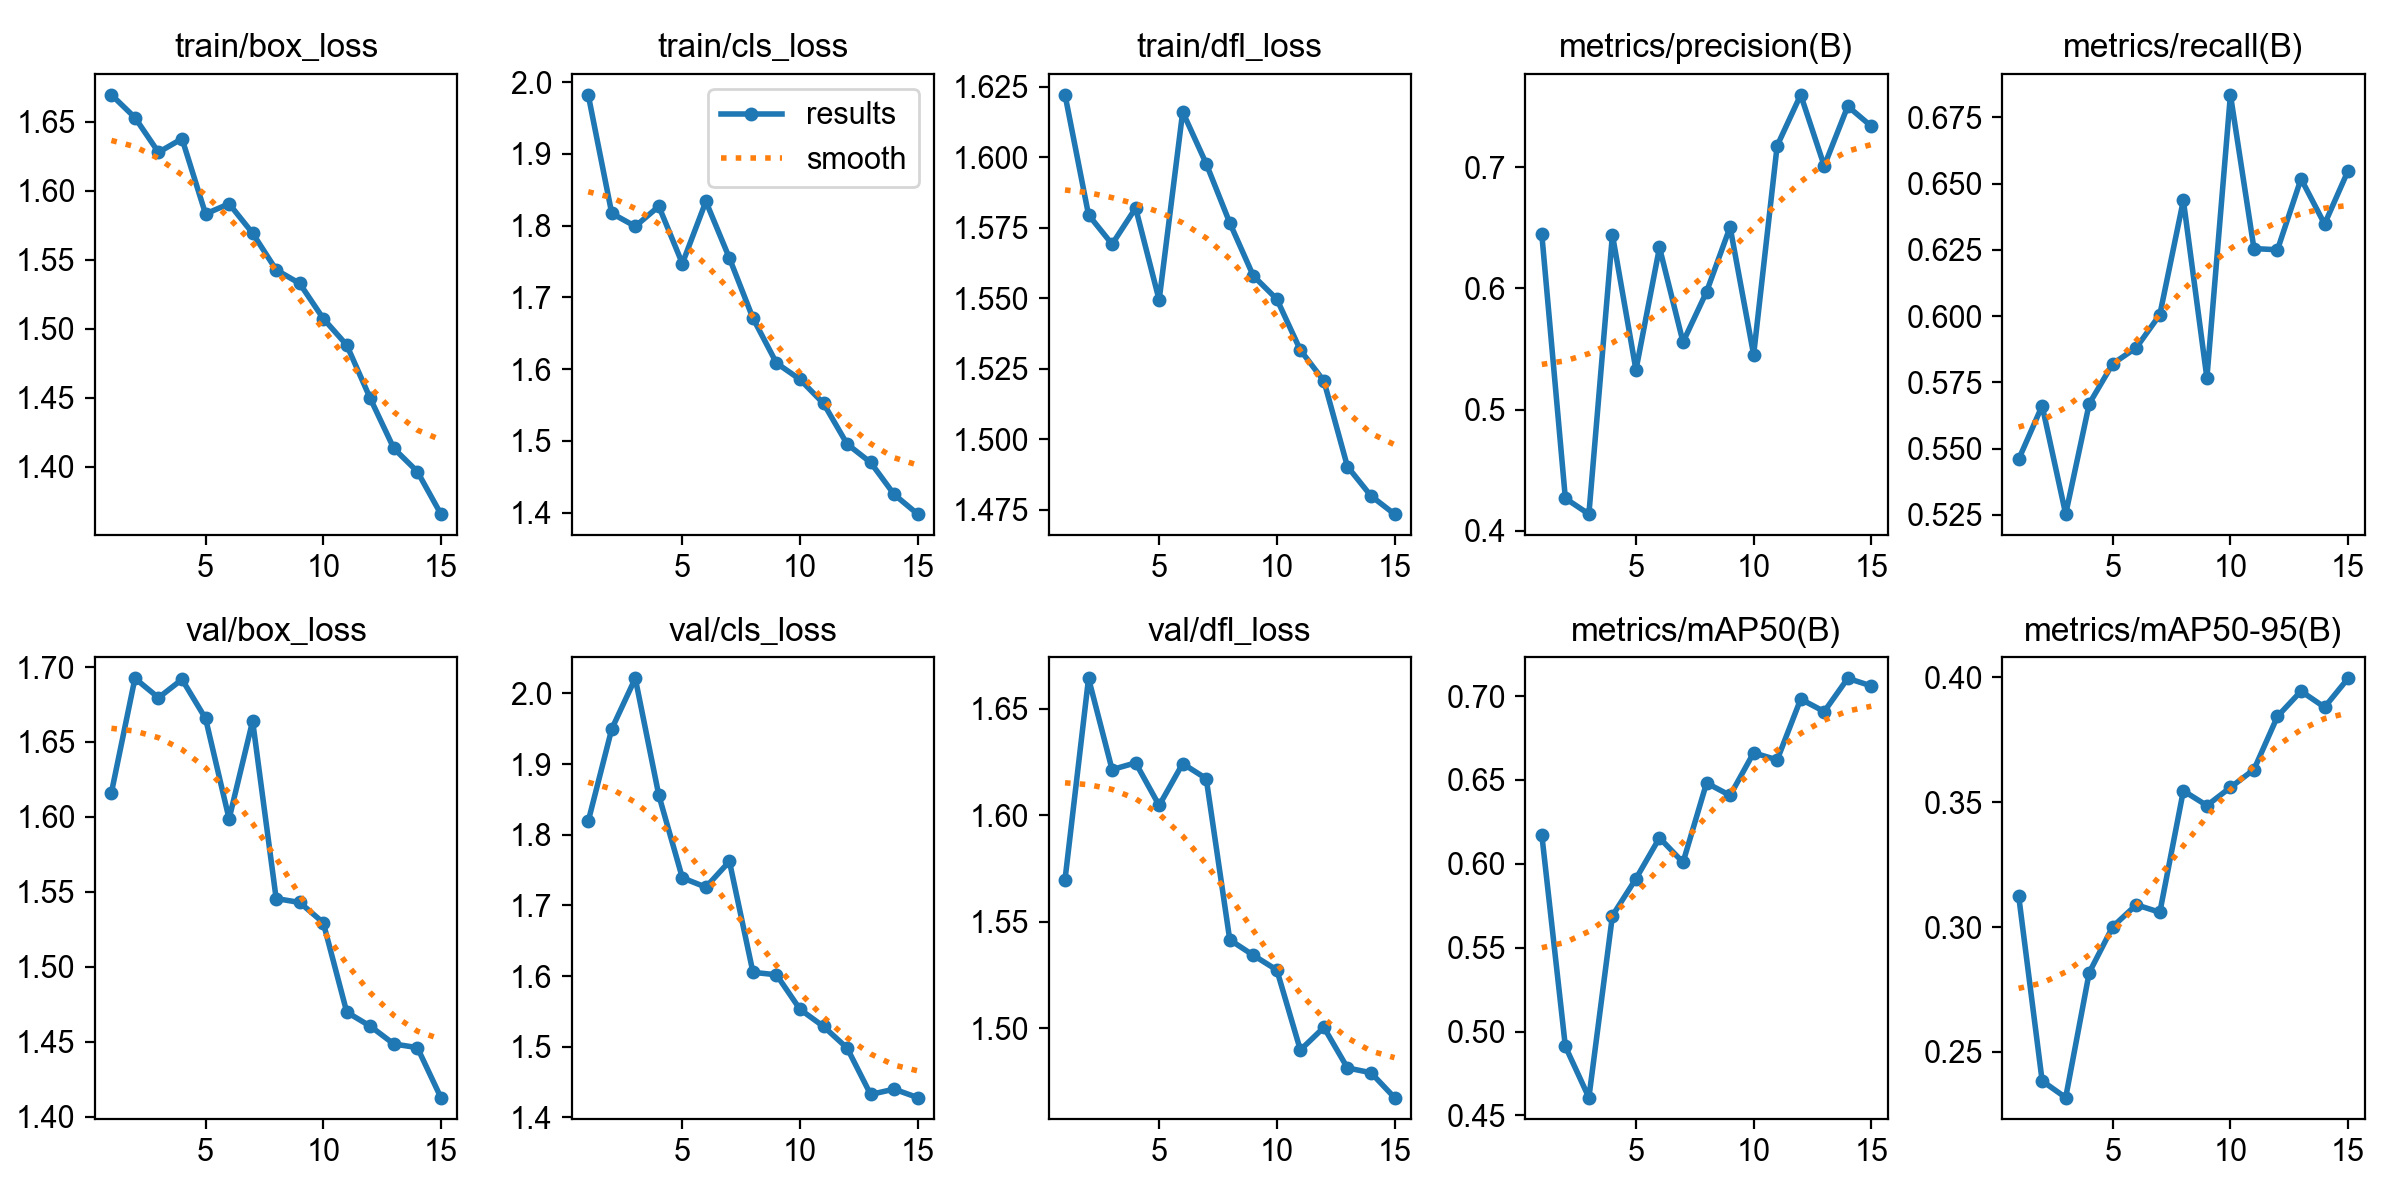

In [40]:
from pathlib import Path
from IPython.display import display, Image

image_path = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_finetuned\results.png"
)

if image_path.exists():
    display(Image(filename=str(image_path)))
else:
    print("Image introuvable :", image_path)

In [41]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection"
)

csv_path = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_finetuned"
    / "results.csv"
)

if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    print("Nombre d'époques :", len(df))
    print("\nColonnes disponibles :")
    print(df.columns.tolist())

    print("\nRésultats des 5 dernières époques :")
    print(df.tail(5).to_string(index=False))
else:
    print("Fichier introuvable :", csv_path)

Nombre d'époques : 15

Colonnes disponibles :
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Résultats des 5 dernières époques :
 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    11 3751.61         1.48807         1.55222         1.53164               0.71779            0.62548           0.66193              0.36303       1.46975       1.52862       1.48985 0.000340 0.000340 0.000340
    12 4362.85         1.44941         1.49574         1.52071               0.75978            0.62503           0.69814              0.38433       1.46035       1.49814       1.50048 0.000274 0.000274 0.000274
    13 4886.02         1.41326         1.47

In [42]:
from pathlib import Path

model_path = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection\runs\yolo11n_neu_finetuned\weights\best.pt"
)

print("Modèle trouvé :", model_path.exists())

if model_path.exists():
    print(
        "Taille du modèle :",
        round(model_path.stat().st_size / (1024 * 1024), 2),
        "Mo"
    )
else:
    print("Vérifie le chemin du fichier best.pt.")

Modèle trouvé : True
Taille du modèle : 5.18 Mo


In [43]:
from pathlib import Path
from ultralytics import YOLO
from IPython.display import display, Image

PROJECT_ROOT = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection"
)

IMAGE_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "NEU-DET"
    / "IMAGES"
    / "rolled-in_scale_250.jpg"
)

MODEL_PATH = (
    PROJECT_ROOT
    / "runs"
    / "yolo11n_neu_finetuned"
    / "weights"
    / "best.pt"
)

model = YOLO(str(MODEL_PATH))

results = model.predict(
    source=str(IMAGE_PATH),
    imgsz=320,
    conf=0.25,
    save=False,
    verbose=False
)

annotated_image = results[0].plot()

display(Image(data=annotated_image[:, :, ::-1].copy()))

In [44]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_ROOT = Path(
    r"C:\Users\yassmine\Downloads\industrial-defect-detection"
)

IMAGE_PATH = (
    PROJECT_ROOT / "data" / "raw" / "NEU-DET"
    / "IMAGES" / "rolled-in_scale_250.jpg"
)

MODEL_PATH = (
    PROJECT_ROOT / "runs" / "yolo11n_neu_finetuned"
    / "weights" / "best.pt"
)

model = YOLO(str(MODEL_PATH))

results = model.predict(
    source=str(IMAGE_PATH),
    imgsz=320,
    conf=0.25,
    verbose=False
)

result = results[0]

print("Image :", IMAGE_PATH.name)
print("Nombre de détections :", len(result.boxes))

for i, box in enumerate(result.boxes, start=1):
    class_id = int(box.cls.item())
    confidence = float(box.conf.item())
    coords = [round(v, 1) for v in box.xyxy[0].tolist()]

    print(
        f"{i}. Classe : {model.names[class_id]} | "
        f"Confiance : {confidence:.1%} | "
        f"Boîte : {coords}"
    )

Image : rolled-in_scale_250.jpg
Nombre de détections : 4
1. Classe : rolled-in_scale | Confiance : 49.5% | Boîte : [151.6, 42.4, 199.6, 199.9]
2. Classe : rolled-in_scale | Confiance : 43.5% | Boîte : [96.5, 0.1, 140.7, 40.5]
3. Classe : rolled-in_scale | Confiance : 42.0% | Boîte : [93.2, 157.1, 145.4, 200.0]
4. Classe : rolled-in_scale | Confiance : 30.9% | Boîte : [69.8, 0.2, 140.7, 39.7]
